# 01 · Exploratory analysis (P14, blinded)

**Blinding rule (CLAUDE.md rule 6):** pre-registration (P15) is not locked, so nothing here compares treated with
untreated editions after a launch. Per-edition series and every cross-edition contrast stop at **2024-04**. Only two
things run past it, and neither compares editions: the total of all 11 core editions combined, and the English
referral mix (one edition, shares).

Source: `panels/panel_lang_month.parquet` (P13). Clickstream outcomes start at 2019-04 (method break, P11). All code
is in `src/wao/viz/eda.py`; tables go to `report/qa/p14_*.csv` and figures to `report/figures/p14_*.png`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from wao.viz import eda
pd.set_option("display.width", 160)
r = eda.main()
plt.close("all")  # shown one by one below

## 1 · Long-run trends (index 2019-04..2020-03 = 100)

Search arrivals (colour by cohort) and user web views (grey). COVID gives a spike in spring 2020 everywhere.
Most editions drift down 2021–22, then level off. **fa** rises steeply (VPN/filtering era; Iran's 2019-11 shutdown is the
dip), **zh** views jump in 2021–22 without a matching search rise, and **en/es/pt** search rises in 2023 while views
stay flat (the rise is mobile web: en mobile +13% 2022→23, desktop −6%).

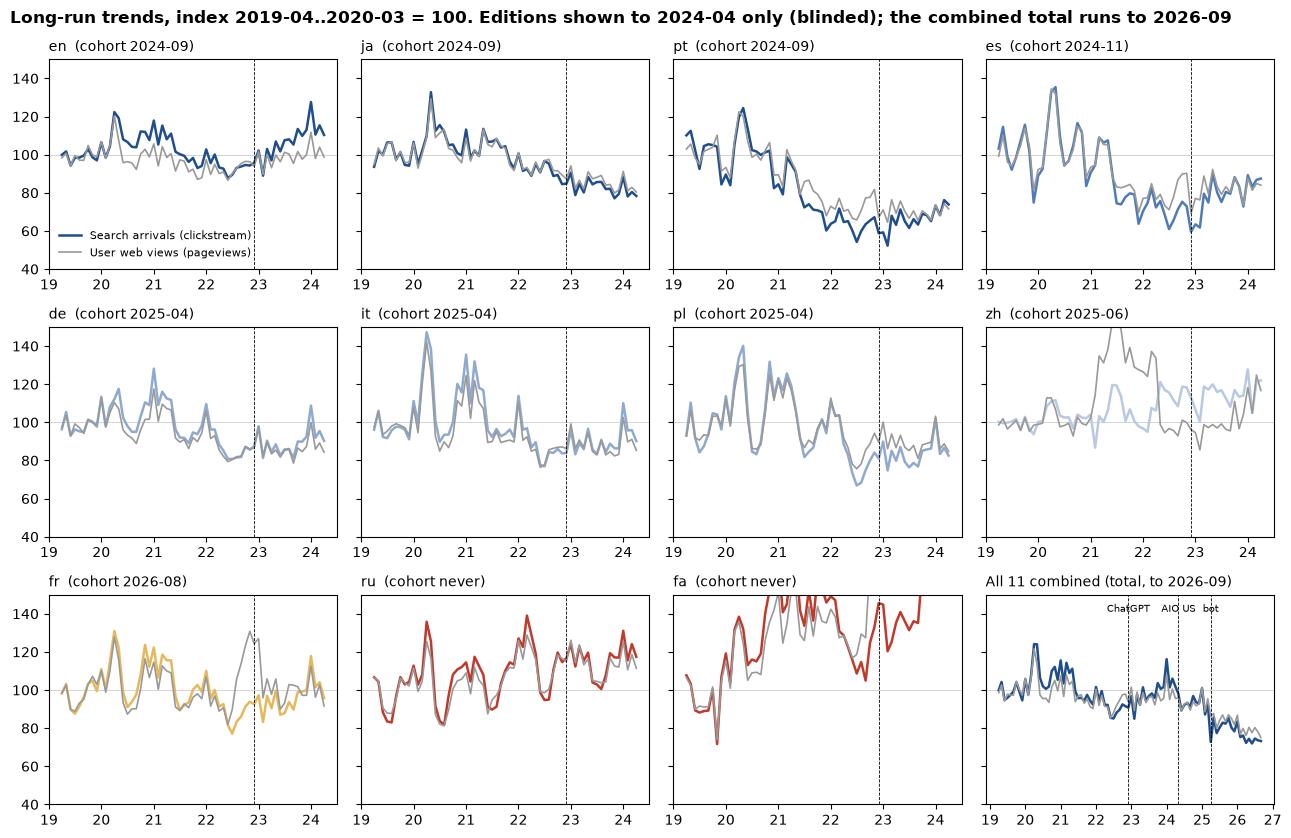

In [2]:
r["figs"]["p14_trends"]

## 2 · Seasonality

Month-of-year factors differ sharply by edition: January peak and summer trough in de/it/pl/fr/ru/fa (school
calendars), March peak and December trough in es/pt (Latin American and Brazilian school years), Chinese New Year dip
in February for zh, almost flat in en. **Common month FE cannot absorb this** → the models need edition-specific
seasonality. Weekday: desktop is a weekday medium (Saturday −15% to −25%), mobile web a weekend one (Sunday +10% to
+25%); fa's weekend is Thursday–Friday.

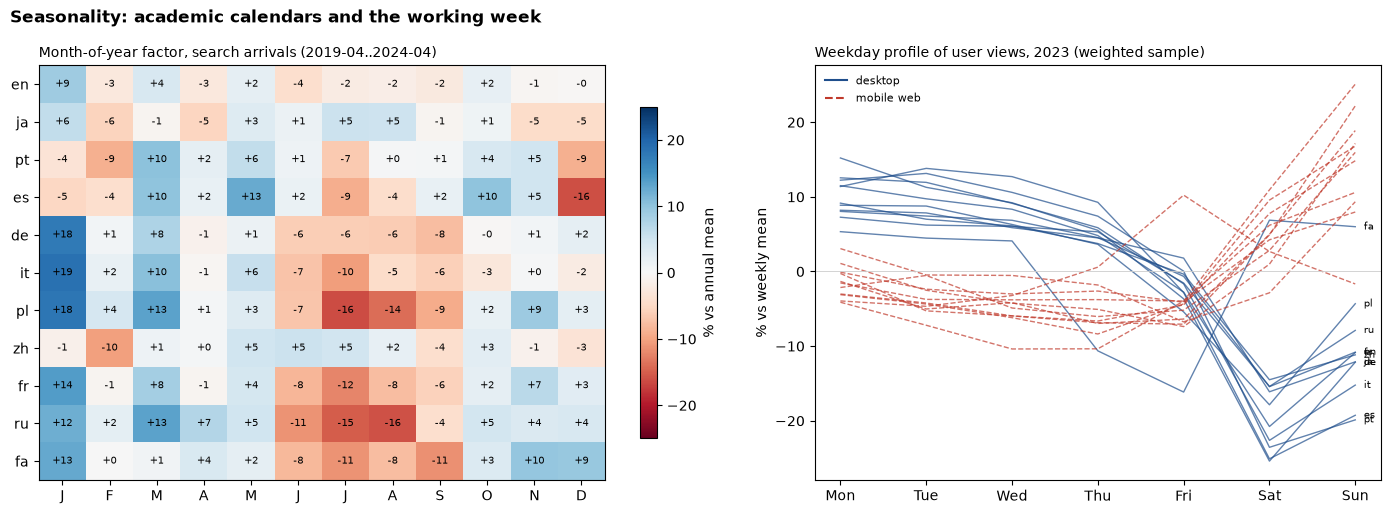

In [3]:
r["figs"]["p14_seasonality"]

In [4]:
display(r["sm"].pivot(index="lang", columns="moy", values="factor").round(0))

moy,1,2,3,4,5,6,7,8,9,10,11,12
lang,,,,,,,,,,,,
de,18.0,1.0,8.0,-1.0,1.0,-6.0,-6.0,-6.0,-8.0,-0.0,1.0,2.0
en,9.0,-3.0,4.0,-3.0,2.0,-4.0,-2.0,-2.0,-2.0,2.0,-1.0,-0.0
es,-5.0,-4.0,10.0,2.0,13.0,2.0,-9.0,-4.0,2.0,10.0,5.0,-16.0
fa,13.0,0.0,1.0,4.0,2.0,-8.0,-11.0,-8.0,-11.0,3.0,10.0,9.0
fr,14.0,-1.0,8.0,-1.0,4.0,-8.0,-12.0,-8.0,-6.0,2.0,7.0,3.0
it,19.0,2.0,10.0,-1.0,6.0,-7.0,-10.0,-5.0,-6.0,-3.0,0.0,-2.0
ja,6.0,-6.0,-1.0,-5.0,3.0,1.0,5.0,5.0,-1.0,1.0,-5.0,-5.0
pl,18.0,4.0,13.0,1.0,3.0,-7.0,-16.0,-14.0,-9.0,2.0,9.0,3.0
pt,-4.0,-9.0,10.0,2.0,6.0,1.0,-7.0,0.0,1.0,4.0,5.0,-9.0


## 3 · How parallel were the editions before 2024-05?

Deseasonalised log search arrivals of each edition minus the leave-one-out mean of the other editions (fa excluded
from the reference: its own +11%/yr drift would tilt every comparison). Gap trend in %/yr, HAC 95% CI, for the full
pre-period and for the 17 months after ChatGPT.

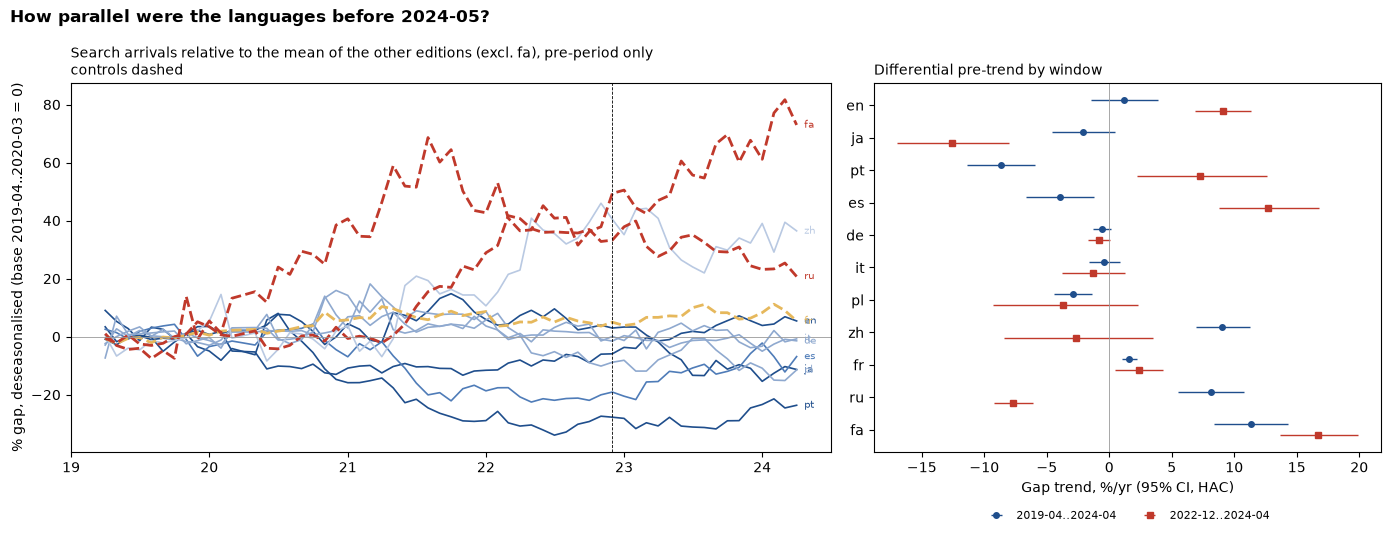

In [5]:
r["figs"]["p14_pretrends"]

In [6]:
display(r["pt"].pivot(index="lang", columns="window", values=["slope", "lo", "hi", "resid_sd_pct"]).round(1).loc[eda.ORDER])

slope                                lo                                hi                      resid_sd_pct                 
window 2019-04..2024-04 2022-12..2024-04 2019-04..2024-04 2022-12..2024-04 2019-04..2024-04 2022-12..2024-04 2019-04..2024-04 2022-12..2024-04
lang                                                                                                                                          
en                  1.2              9.1             -1.5              6.9              3.9             11.4              6.1              1.5
ja                 -2.1            -12.6             -4.6            -17.0              0.5             -8.0              6.4              3.6
pt                 -8.7              7.3            -11.4              2.2             -6.0             12.6              8.1              3.4
es                 -4.0             12.7             -6.6              8.8             -1.2             16.8              7.8              3.2
de                 -0.6             -0.8             -1.3             -1.7              0.1              0.1              2.5              1.3
it                 -0.4             -1.3             -1.7             -3.8              0.9              1.2              4.7              2.6
pl                 -2.9             -3.7             -4.4             -9.3             -1.4              2.3              5.5              4.3
zh                  9.0             -2.6              6.9             -8.4             11.2              3.5              7.3              4.7
fr                  1.6              2.4              1.0              0.5              2.2              4.3              2.2              1.7
ru                  8.1             -7.7              5.5             -9.2             10.8             -6.1              7.6              2.3
fa                 11.3             16.7              8.4             13.7             14.3             19.9              9.1              3.3

- **Parallel:** de, it (gap trend within ±1.3%/yr in both windows, residual SD 1–3%), fr (+1.6 to +2.4%/yr,
  SD ~2%; the most stable control).
- **Not parallel in the run-up:** en (+9%/yr), es (+13%/yr), pt (+7%/yr) rise relative to the rest in 2022-12..2024-04,
  while ja falls (−13%/yr). ru (+8%/yr overall, then −8%/yr after its 2022 surge) and fa (+11 to +17%/yr, SD 9%) are
  the least parallel of all.
- zh drifts +9%/yr over the whole window but is flat since 2022-12, with wide noise.

## 4 · English referral mix, 2017-11..2026-09 (descriptive)

One edition, shares only (allowed). Search is 42–48% of arrivals throughout; it rose from 42% (late 2022) to 48%
(early 2024). Faded area = before the 2019-04 method change.

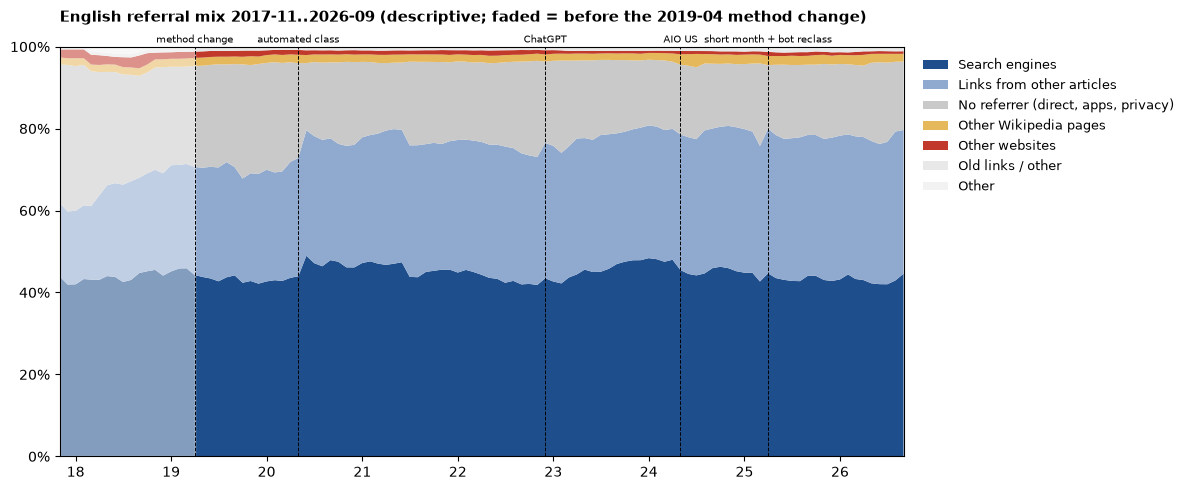

In [7]:
r["figs"]["p14_referral_mix_en"]

## 5 · The ChatGPT era in the pre-period

Per edition: log outcome on a linear trend with a kink at 2022-12, month-of-year FE and shock dummies (COVID
2020-03..05, fa 2019-11, en step from 2020-05). Trend before vs after the kink, %/yr.

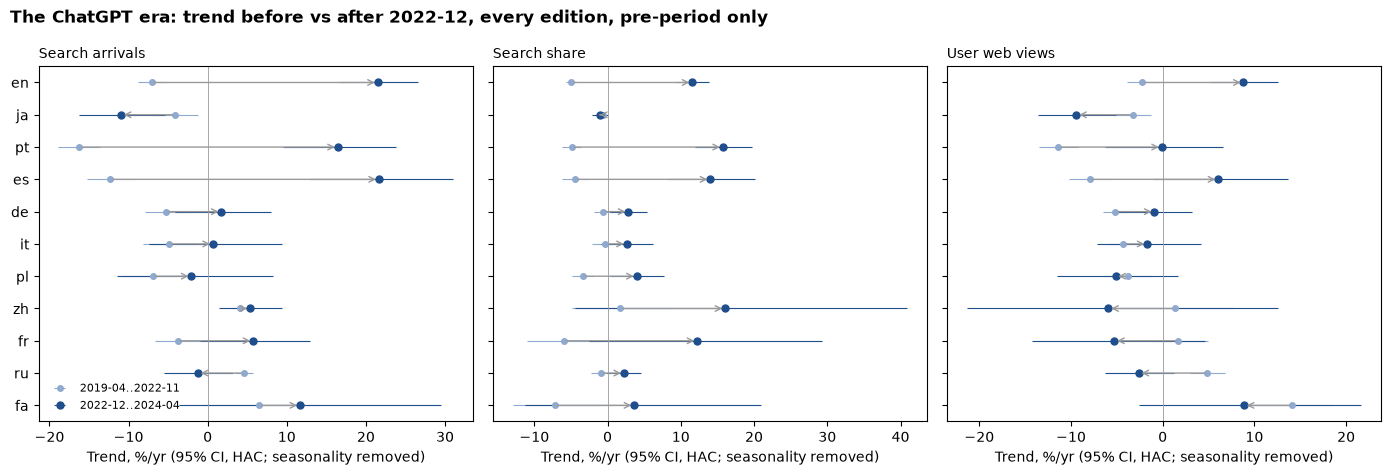

In [8]:
r["figs"]["p14_chatgpt_era"]

In [9]:
display(r["tm"].pivot(index="lang", columns="outcome", values=["pre_gpt", "post_gpt", "change_p"]).round(2).loc[eda.ORDER])

pre_gpt              post_gpt              change_p            
outcome  search share  views   search  share views   search share views
lang                                                                   
en        -7.10 -4.96  -2.24    21.47  11.56  8.81     0.00  0.00  0.00
ja        -4.09 -0.63  -3.28   -10.96  -1.04 -9.42     0.08  0.61  0.04
pt       -16.25 -4.91 -11.38    16.43  15.73 -0.10     0.00  0.00  0.00
es       -12.33 -4.41  -7.98    21.62  14.01  6.04     0.00  0.00  0.00
de        -5.32 -0.55  -5.16     1.73   2.82 -0.91     0.07  0.06  0.08
it        -4.88 -0.30  -4.33     0.65   2.60 -1.69     0.30  0.27  0.42
pl        -6.95 -3.37  -3.82    -2.06   3.96 -5.14     0.44  0.00  0.75
zh         4.03  1.72   1.29     5.34  16.04 -5.92     0.58  0.31  0.53
fr        -3.81 -5.96   1.71     5.75  12.23 -5.27     0.03  0.07  0.28
ru         4.53 -0.90   4.88    -1.23   2.23 -2.61     0.03  0.08  0.00
fa         6.46 -7.19  14.11    11.67   3.63  8.86     0.65  0.31  0.52

- **No sign of a ChatGPT-era decline in search arrivals** through 2024-04: the trend improves after 2022-12 in 8 of 11
  editions; en/es/pt swing from −7…−16%/yr to +16…+22%/yr. The exceptions are **ja** (−4 → −11%/yr) and **ru**
  (+5 → −1%/yr, after the 2022 war-period surge).
- Search share rises in most editions after 2022-12, so it is not just a views effect.
- For P16/P25: a ChatGPT break in English is *positive*, not negative, in this window; the en/es/pt 2023 surge is
  mobile-web traffic and could include undetected automation later removed by the 2025-04 bot reclassification.

## Verdict on the controls

| Edition | Role | Usable? |
|---|---|---|
| fr | late-treated control | **Yes**: most parallel (gap +1.6 to +2.4%/yr, SD ~2%) |
| ru | partial dose | **With care**: trend break in 2022 (+8 → −8%/yr); keep for dose-response, not as a level control |
| fa | near-untreated control | **No, as a parallel control**: +11 to +17%/yr relative drift, SD 9%, shutdowns; negative-control use only |

Implications for P15: edition-specific seasonality; event-study leads plus a pre-trend sensitivity bound
(Rambachan–Roth) because en/es/pt/ja are not parallel in 2023; decide whether fa enters the primary comparison group.